<a href="https://colab.research.google.com/github/Nakib-Nasrullah/Research-Skill/blob/main/Naive_Bayes_SVM_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification with Naive Bayes

**Dataset:** Breast Cancer Wisconsin (Diagnostic) Data Set  
**Instructor:** Md. Samiul Islam  
**Organization:** Skill Morph Research Lab

In [ ]:
# Mount Google Drive and import libraries
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Load Dataset
Read the Breast Cancer Wisconsin dataset and explore basic information.

In [ ]:
# Load dataset
df = pd.read_csv('/content/drive/MyDrive/datasets/Breast_Cancer_Wisconsin_Dataset.csv')

print("First few rows:")
print(df.head())


First few rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_w

In [ ]:
print("\nDataset shape:", df.shape)



Dataset shape: (569, 33)


In [ ]:
print("\nColumn names:")
print(df.columns.tolist())



Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


In [ ]:
print("\nDataset info:")
print(df.info())


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_s

In [ ]:
# Drop ID, Unnamed, and empty columns
cols_to_drop = [col for col in df.columns if 'id' in col.lower() or 'unnamed' in col.lower() or col == '']
df = df.drop(columns=cols_to_drop, errors='ignore')

# Remove rows with any missing values
df = df.dropna()

print("Dropped columns:", cols_to_drop)
print("Shape after cleaning:", df.shape)
print("Remaining columns:", len(df.columns))

Dropped columns: ['id', 'Unnamed: 32']
Shape after cleaning: (569, 31)
Remaining columns: 31


## Prepare Features and Target
Convert diagnosis to binary: M (Malignant) = 1, B (Benign) = 0

In [ ]:
# Define the target column name
target_col = 'diagnosis'

print("Target column:", target_col)

# Encode target variable
df[target_col] = df[target_col].map({'M': 1, 'B': 0})

# Separate features and target
# We drop the target column and select only numeric features
X = df.drop(columns=[target_col]).select_dtypes(include=[np.number])
y = df[target_col]

print("Features shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Target column: diagnosis
Features shape: (569, 30)
Target distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


## Train-Test Split
Split data into 80% training and 20% testing sets.

In [ ]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])
print("\nTrain class distribution:")
print(y_train.value_counts())
print("\nTest class distribution:")
print(y_test.value_counts())

Training set size: 455
Testing set size: 114

Train class distribution:
diagnosis
0    291
1    164
Name: count, dtype: int64

Test class distribution:
diagnosis
0    66
1    48
Name: count, dtype: int64


## Naive Bayes Classifier
Train Gaussian Naive Bayes and evaluate performance.

In [ ]:
# Train Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_nb = nb_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(nb_accuracy, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.9561

Confusion Matrix:
[[65  1]
 [ 4 44]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96        66
           1       0.98      0.92      0.95        48

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Visualization
Compare confusion matrices of both models.

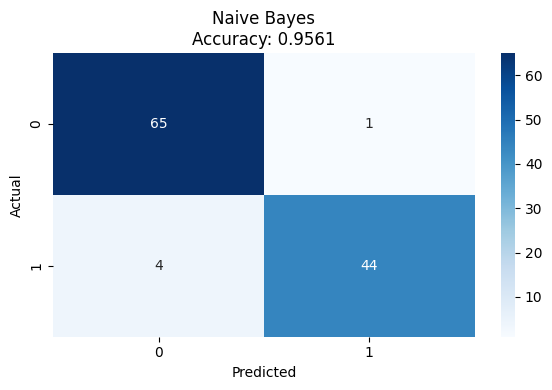

In [ ]:
# Plot confusion matrix
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

# Naive Bayes confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title(f'Naive Bayes\nAccuracy: {nb_accuracy:.4f}')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Assignment

Complete the following tasks and submit your modified notebook:

**Task 1:** Take a dataset from Kaggle

**Task 2:** Evaluate both models using precision, recall, and F1-score.  
**Task 3:** Try changing the test size (e.g., 30%) and compare results.